# 01 · Exploração e qualidade dos dados da Olist

Este notebook analisa os nove CSVs da [Olist no Kaggle](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce) para apoiar decisões sobre vendas, entregas e experiência do cliente. A fonte descreve uma amostra histórica anonimizada de pedidos realizados em diferentes marketplaces.

As consultas usam os arquivos originais em modo de leitura. Conversões de datas, filtros e comparações textuais são locais à análise. Os resultados exibidos são agregados.

## 1. Leitura e perfil das tabelas

Os IDs textuais e prefixos de CEP são lidos como texto para preservar a representação do CSV. Campos CSV vazios são reconhecidos como ausentes. Datas ficam em texto no DataFrame original e são interpretadas em uma seção própria.

In [1]:
from math import isclose
from pathlib import Path
import sys
from unicodedata import normalize

import duckdb
from IPython.display import Markdown, display
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

%matplotlib inline

projeto = next(
    (pasta for pasta in (Path.cwd(), *Path.cwd().parents)
     if (pasta / "src" / "validation" / "check_raw_files.py").is_file()),
    None,
)
if projeto is None:
    raise FileNotFoundError("Abra o notebook a partir de uma pasta do projeto Olist Analytics.")
sys.path.insert(0, str(projeto))

from src.validation.check_raw_files import raw_csv_paths

pd.set_option("display.max_rows", 60)
pd.set_option("display.max_columns", 16)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 140)


def mostrar(titulo, tabela):
    """Exibe uma tabela agregada, com até quatro casas nos resultados numéricos."""
    display(Markdown(f"**{titulo}**"))
    display(tabela.round(4))


def ler_csv(caminho):
    """Lê o arquivo com IDs e prefixos de CEP como texto."""
    opcoes = {"encoding": "utf-8-sig", "keep_default_na": False, "na_values": [""]}
    colunas = pd.read_csv(caminho, nrows=0, **opcoes).columns
    tipos_textuais = {
        coluna: "string"
        for coluna in colunas
        if (coluna.endswith("_id") and coluna != "order_item_id")
        or coluna.endswith("_zip_code_prefix")
    }
    return pd.read_csv(caminho, dtype=tipos_textuais, **opcoes)


caminhos = raw_csv_paths(projeto / "data" / "raw")
ausentes = [caminho.name for caminho in caminhos if not caminho.is_file()]
if ausentes:
    raise FileNotFoundError(f"CSVs ausentes em data/raw: {', '.join(ausentes)}")

tabelas = {
    caminho.stem.removeprefix("olist_").removesuffix("_dataset"): ler_csv(caminho)
    for caminho in caminhos
}
assert len(tabelas) == len(caminhos) == 9

clientes = tabelas["customers"]
geo = tabelas["geolocation"]
itens = tabelas["order_items"]
pagamentos = tabelas["order_payments"]
avaliacoes = tabelas["order_reviews"]
pedidos = tabelas["orders"]
produtos = tabelas["products"]
vendedores = tabelas["sellers"]
categorias = tabelas["product_category_name_translation"]

In [2]:
resumo = pd.DataFrame.from_dict({
    nome: {
        "linhas": len(tabela),
        "colunas": tabela.shape[1],
        "linhas com algum nulo": tabela.isna().any(axis=1).sum(),
        "duplicatas exatas excedentes": tabela.duplicated().sum(),
    }
    for nome, tabela in tabelas.items()
}, orient="index").rename_axis("tabela")
mostrar("Volume e duplicatas exatas. A primeira ocorrência de cada linha fica fora da contagem de excedentes.", resumo)

partes_perfil = []
for nome, tabela in tabelas.items():
    nulos = tabela.isna().sum()
    partes_perfil.append(pd.DataFrame({
        "tabela": nome,
        "coluna": tabela.columns,
        "tipo carregado": tabela.dtypes.astype(str).to_numpy(),
        "nulos": nulos.to_numpy(),
        "nulos (%)": nulos.to_numpy() * 100 / len(tabela),
        "valores distintos não nulos": tabela.nunique().to_numpy(),
    }))
perfil_colunas = pd.concat(partes_perfil, ignore_index=True)
assert len(perfil_colunas) == resumo["colunas"].sum()
mostrar("Tipos, ausências e cardinalidade por coluna", perfil_colunas)

numericos = []
for nome, tabela in tabelas.items():
    for coluna in tabela.select_dtypes(include="number"):
        valores = tabela[coluna].dropna()
        p01, p25, p50, p75, p95, p99 = valores.quantile([.01, .25, .50, .75, .95, .99])
        iqr = p75 - p25
        extremos = pd.NA if iqr == 0 else (
            (valores < p25 - 1.5 * iqr) | (valores > p75 + 1.5 * iqr)
        ).sum()
        numericos.append({
            "tabela": nome, "coluna": coluna, "n": len(valores), "mínimo": valores.min(),
            "p01": p01, "p25": p25, "mediana": p50, "p75": p75, "p95": p95,
            "p99": p99, "máximo": valores.max(), "extremos IQR": extremos,
        })
perfil_numerico = pd.DataFrame(numericos)
mostrar("Distribuições numéricas e extremos pelo intervalo interquartil", perfil_numerico)

**Volume e duplicatas exatas. A primeira ocorrência de cada linha fica fora da contagem de excedentes.**

,linhas,colunas,linhas com algum nulo,duplicatas exatas excedentes
tabela,,,,
customers,99441,5,0,0
geolocation,1000163,5,0,261831
order_items,112650,7,0,0
order_payments,103886,5,0,0
order_reviews,99224,7,89385,0
orders,99441,8,2980,0
products,32951,9,611,0
sellers,3095,4,0,0
product_category_name_translation,71,2,0,0


**Tipos, ausências e cardinalidade por coluna**

,tabela,coluna,tipo carregado,nulos,nulos (%),valores distintos não nulos
0,customers,customer_id,string,0,0.0000,99441
1,customers,customer_unique_id,string,0,0.0000,96096
2,customers,customer_zip_code_prefix,string,0,0.0000,14994
3,customers,customer_city,object,0,0.0000,4119
4,customers,customer_state,object,0,0.0000,27
5,geolocation,geolocation_zip_code_prefix,string,0,0.0000,19015
6,geolocation,geolocation_lat,float64,0,0.0000,717360
7,geolocation,geolocation_lng,float64,0,0.0000,717613
8,geolocation,geolocation_city,object,0,0.0000,8011
9,geolocation,geolocation_state,object,0,0.0000,27


**Distribuições numéricas e extremos pelo intervalo interquartil**

,tabela,coluna,n,mínimo,p01,p25,mediana,p75,p95,p99,máximo,extremos IQR
0,geolocation,geolocation_lat,1000163,-36.6054,-30.1045,-23.6035,-22.9194,-19.9796,-7.6739,-2.5010,45.0659,168240
1,geolocation,geolocation_lng,1000163,-101.4668,-57.6507,-48.5732,-46.6379,-43.7677,-38.5044,-34.9386,121.1054,42348
2,order_items,order_item_id,112650,1.0000,1.0000,1.0000,1.0000,1.0000,2.0000,4.0000,21.0000,<NA>
3,order_items,price,112650,0.8500,9.9900,39.9000,74.9900,134.9000,349.9000,890.0000,6735.0000,8427
4,order_items,freight_value,112650,0.0000,4.4198,13.0800,16.2600,21.1500,45.1200,84.5200,409.6800,12134
5,order_payments,payment_sequential,103886,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,3.0000,29.0000,<NA>
6,order_payments,payment_installments,103886,0.0000,1.0000,1.0000,1.0000,4.0000,10.0000,10.0000,24.0000,6313
7,order_payments,payment_value,103886,0.0000,6.6900,56.7900,100.0000,171.8375,437.6350,1039.9165,13664.0800,7981
8,order_reviews,review_score,99224,1.0000,1.0000,4.0000,5.0000,5.0000,5.0000,5.0000,5.0000,14575
9,products,product_name_lenght,32341,5.0000,20.0000,42.0000,51.0000,57.0000,60.0000,63.0000,76.0000,290


O limite exploratório de extremos é de 1,5 vezes o intervalo interquartil abaixo de P25 ou acima de P75. Quando o intervalo é zero, a coluna fica sem essa marcação. A marcação é um sinal para investigação, especialmente em distribuições assimétricas e campos discretos como notas e sequências.

Para categorias, as frequências abaixo usam até cinco valores por campo selecionado, com percentuais sobre a tabela de origem. IDs e textos livres são resumidos por cardinalidade e nulos. As distribuições completas de status e notas aparecem na seção de negócio.

In [3]:
campos_categoricos = {
    "customers": ("customer_state", "customer_city"),
    "geolocation": ("geolocation_state", "geolocation_city"),
    "order_payments": ("payment_type",),
    "orders": ("order_status",),
    "products": ("product_category_name",),
    "sellers": ("seller_state", "seller_city"),
}
frequencias = []
for nome, campos in campos_categoricos.items():
    tabela = tabelas[nome]
    for coluna in campos:
        contagens = tabela[coluna].value_counts(dropna=False).head(5)
        for valor, quantidade in contagens.items():
            frequencias.append({
                "tabela": nome, "coluna": coluna,
                "valor": "Ausente" if pd.isna(valor) else valor,
                "linhas": quantidade, "% da tabela": quantidade * 100 / len(tabela),
            })
mostrar("Categorias mais frequentes por campo", pd.DataFrame(frequencias))

**Categorias mais frequentes por campo**

,tabela,coluna,valor,linhas,% da tabela
0,customers,customer_state,SP,41746,41.9807
1,customers,customer_state,RJ,12852,12.9242
2,customers,customer_state,MG,11635,11.7004
3,customers,customer_state,RS,5466,5.4967
4,customers,customer_state,PR,5045,5.0734
5,customers,customer_city,sao paulo,15540,15.6274
6,customers,customer_city,rio de janeiro,6882,6.9207
7,customers,customer_city,belo horizonte,2773,2.7886
8,customers,customer_city,brasilia,2131,2.1430
9,customers,customer_city,curitiba,1521,1.5296


## 2. Chaves, granularidade e cobertura dos relacionamentos

Uma chave candidata é avaliada pela presença, pela cardinalidade e pela repetição. “Excedentes” conta ocorrências após a primeira. “Linhas em chaves repetidas” conta todas as ocorrências envolvidas.

Na cobertura, A é a tabela de origem da busca e B é a tabela consultada. A cardinalidade usa as multiplicidades observadas **entre chaves presentes dos dois lados**. Nulos e chaves preenchidas sem correspondência têm contagens independentes, em ambos os sentidos.

In [4]:
chaves_candidatas = {
    "customers": [("customer_id",), ("customer_unique_id",)],
    "geolocation": [
        ("geolocation_zip_code_prefix",),
        ("geolocation_zip_code_prefix", "geolocation_lat", "geolocation_lng"),
        tuple(geo.columns),
    ],
    "order_items": [("order_id", "order_item_id"), ("order_id",)],
    "order_payments": [("order_id", "payment_sequential"), ("order_id",)],
    "order_reviews": [("review_id",), ("order_id", "review_id"), ("order_id",)],
    "orders": [("order_id",), ("customer_id",)],
    "products": [("product_id",)],
    "sellers": [("seller_id",)],
    "product_category_name_translation": [("product_category_name",)],
}
perfis_chaves = []
for nome, candidatos in chaves_candidatas.items():
    for colunas in candidatos:
        campos = tabelas[nome][list(colunas)]
        preenchidas = campos.dropna()
        perfis_chaves.append({
            "tabela": nome, "chave testada": " + ".join(colunas),
            "linhas com chave nula": len(campos) - len(preenchidas),
            "chaves distintas": len(preenchidas.drop_duplicates()),
            "repetições excedentes": preenchidas.duplicated().sum(),
            "linhas em chaves repetidas": preenchidas.duplicated(keep=False).sum(),
        })
mostrar("Candidatas a chave e outras colunas de junção", pd.DataFrame(perfis_chaves))


def cobertura_relacao(origem, chave_origem, destino, chave_destino):
    """Mede a cobertura sem materializar o produto das chaves repetidas."""
    lado_a = tabelas[origem][chave_origem]
    lado_b = tabelas[destino][chave_destino]
    contagem_a = lado_a.value_counts()
    contagem_b = lado_b.value_counts()
    comuns = contagem_a.index.intersection(contagem_b.index)

    def multiplicidade(contagem):
        return "N" if contagem.loc[comuns].gt(1).any() else "1"

    comuns_a = int(contagem_a.loc[comuns].sum())
    comuns_b = int(contagem_b.loc[comuns].sum())
    nulos_a = int(lado_a.isna().sum())
    nulos_b = int(lado_b.isna().sum())
    fora_a = contagem_a.index.difference(comuns)
    fora_b = contagem_b.index.difference(comuns)
    linhas_fora_a = int(contagem_a.loc[fora_a].sum())
    linhas_fora_b = int(contagem_b.loc[fora_b].sum())
    assert comuns_a + linhas_fora_a + nulos_a == len(lado_a)
    assert comuns_b + linhas_fora_b + nulos_b == len(lado_b)
    return {
        "relação A → B": f"{origem}.{chave_origem} → {destino}.{chave_destino}",
        "cardinalidade A:B": f"{multiplicidade(contagem_a)}:{multiplicidade(contagem_b)}"
        if len(comuns) else "sem correspondência",
        "chaves comuns": len(comuns),
        "A linhas com par": comuns_a, "A nulos": nulos_a,
        "A linhas sem par": linhas_fora_a, "A chaves sem par": len(fora_a),
        "B linhas com par": comuns_b, "B nulos": nulos_b,
        "B linhas sem par": linhas_fora_b, "B chaves sem par": len(fora_b),
    }


relacoes = [
    ("orders", "customer_id", "customers", "customer_id"),
    ("order_items", "order_id", "orders", "order_id"),
    ("order_payments", "order_id", "orders", "order_id"),
    ("order_reviews", "order_id", "orders", "order_id"),
    ("order_items", "product_id", "products", "product_id"),
    ("order_items", "seller_id", "sellers", "seller_id"),
    ("products", "product_category_name", "product_category_name_translation", "product_category_name"),
    ("customers", "customer_zip_code_prefix", "geolocation", "geolocation_zip_code_prefix"),
    ("sellers", "seller_zip_code_prefix", "geolocation", "geolocation_zip_code_prefix"),
]
cobertura = pd.DataFrame([cobertura_relacao(*relacao) for relacao in relacoes]).set_index("relação A → B")
mostrar("Cardinalidade e correspondência em ambos os sentidos", cobertura)

**Candidatas a chave e outras colunas de junção**

,tabela,chave testada,linhas com chave nula,chaves distintas,repetições excedentes,linhas em chaves repetidas
0,customers,customer_id,0,99441,0,0
1,customers,customer_unique_id,0,96096,3345,6342
2,geolocation,geolocation_zip_code_prefix,0,19015,981148,999120
3,geolocation,geolocation_zip_code_prefix + geolocation_lat + geolocation_lng,0,720154,280009,411716
4,geolocation,geolocation_zip_code_prefix + geolocation_lat + geolocation_lng + geolocation_city + geolocation_state,0,738332,261831,390005
5,order_items,order_id + order_item_id,0,112650,0,0
6,order_items,order_id,0,98666,13984,23787
7,order_payments,order_id + payment_sequential,0,103886,0,0
8,order_payments,order_id,0,99440,4446,7407
9,order_reviews,review_id,0,98410,814,1603


**Cardinalidade e correspondência em ambos os sentidos**

,cardinalidade A:B,chaves comuns,A linhas com par,A nulos,A linhas sem par,A chaves sem par,B linhas com par,B nulos,B linhas sem par,B chaves sem par
relação A → B,,,,,,,,,,
orders.customer_id → customers.customer_id,1:1,99441,99441,0,0,0,99441,0,0,0
order_items.order_id → orders.order_id,N:1,98666,112650,0,0,0,98666,0,775,775
order_payments.order_id → orders.order_id,N:1,99440,103886,0,0,0,99440,0,1,1
order_reviews.order_id → orders.order_id,N:1,98673,99224,0,0,0,98673,0,768,768
order_items.product_id → products.product_id,N:1,32951,112650,0,0,0,32951,0,0,0
order_items.seller_id → sellers.seller_id,N:1,3095,112650,0,0,0,3095,0,0,0
products.product_category_name → product_category_name_translation.product_category_name,N:1,71,32328,610,13,2,71,0,0,0
customers.customer_zip_code_prefix → geolocation.geolocation_zip_code_prefix,N:N,14837,99163,0,278,157,968299,0,31864,4178
sellers.seller_zip_code_prefix → geolocation.geolocation_zip_code_prefix,N:N,2239,3088,0,7,7,268816,0,731347,16776


In [5]:
assert pedidos["order_id"].is_unique and pedidos["order_id"].notna().all()
por_pedido = pd.DataFrame(index=pd.Index(pedidos["order_id"], name="order_id"))
for nome, tabela in (("itens", itens), ("pagamentos", pagamentos), ("avaliações", avaliacoes)):
    por_pedido[nome] = tabela.groupby("order_id").size().reindex(por_pedido.index, fill_value=0)

multiplicidades = pd.DataFrame({
    "sem linha filha": por_pedido.eq(0).sum(),
    "com uma": por_pedido.eq(1).sum(),
    "com duas ou mais": por_pedido.gt(1).sum(),
    "máximo por pedido": por_pedido.max(),
})
assert multiplicidades.iloc[:, :3].sum(axis=1).eq(len(pedidos)).all()
mostrar("Linhas filhas por pedido, incluindo pedidos sem correspondência", multiplicidades)

pedidos_por_cliente = (
    pedidos[["customer_id"]]
    .merge(clientes[["customer_id", "customer_unique_id"]], on="customer_id", validate="many_to_one")
    .groupby("customer_unique_id")
    .size()
)
mostrar("Pedidos por identificador persistente de cliente", pd.DataFrame({
    "clientes identificados": [len(pedidos_por_cliente)],
    "com um pedido": [pedidos_por_cliente.eq(1).sum()],
    "com dois ou mais": [pedidos_por_cliente.gt(1).sum()],
    "máximo": [pedidos_por_cliente.max()],
    "% com dois ou mais": [pedidos_por_cliente.gt(1).mean() * 100],
}))

# Cada LEFT JOIN preserva uma linha mesmo quando não há registro filho.
fatores = por_pedido.clip(lower=1)
desdobramento = pd.Series({
    "pedidos": len(pedidos),
    "+ itens": fatores["itens"].sum(),
    "+ pagamentos": (fatores["itens"] * fatores["pagamentos"]).sum(),
    "+ avaliações": fatores.prod(axis=1).sum(),
}, name="linhas").to_frame()
mostrar("Projeção do LEFT JOIN sucessivo, a partir dos pedidos", desdobramento)

valores_itens = itens.groupby("order_id")[["price", "freight_value"]].sum().reindex(por_pedido.index)
valores_pagos = pagamentos.groupby("order_id")["payment_value"].sum().reindex(por_pedido.index)
efeito_join = pd.DataFrame({
    "sem multiplicar linhas (R$)": [
        valores_itens["price"].sum(), valores_itens["freight_value"].sum(), valores_pagos.sum()
    ],
    "LEFT JOIN em cascata (R$)": [
        (valores_itens["price"] * fatores["pagamentos"] * fatores["avaliações"]).sum(),
        (valores_itens["freight_value"] * fatores["pagamentos"] * fatores["avaliações"]).sum(),
        (valores_pagos * fatores["itens"] * fatores["avaliações"]).sum(),
    ],
}, index=["preço dos itens", "frete dos itens", "valor dos pagamentos"])
efeito_join["aumento (%)"] = (
    efeito_join.iloc[:, 1] / efeito_join.iloc[:, 0] - 1
) * 100

with duckdb.connect(":memory:") as conexao:
    conexao.register("pedidos", pedidos[["order_id"]])
    conexao.register("itens", itens[["order_id", "price", "freight_value"]])
    conexao.register("pagamentos", pagamentos[["order_id", "payment_value"]])
    conexao.register("avaliacoes", avaliacoes[["order_id"]])
    contagem_sql, *somas_sql = conexao.execute("""
        SELECT COUNT(*), SUM(i.price), SUM(i.freight_value), SUM(p.payment_value)
        FROM pedidos AS o
        LEFT JOIN itens AS i USING (order_id)
        LEFT JOIN pagamentos AS p USING (order_id)
        LEFT JOIN avaliacoes AS a USING (order_id)
    """).fetchone()

assert contagem_sql == desdobramento.iloc[-1, 0]
assert all(
    isclose(estimado, observado, rel_tol=0, abs_tol=0.01)
    for estimado, observado in zip(efeito_join.iloc[:, 1], somas_sql, strict=True)
)
mostrar("Efeito do JOIN nas somas. Projeção conferida com SQL no DuckDB.", efeito_join.round(2))

**Linhas filhas por pedido, incluindo pedidos sem correspondência**

,sem linha filha,com uma,com duas ou mais,máximo por pedido
itens,775,88863,9803,21
pagamentos,1,96479,2961,29
avaliações,768,98126,547,3


**Pedidos por identificador persistente de cliente**

,clientes identificados,com um pedido,com dois ou mais,máximo,% com dois ou mais
0,96096,93099,2997,17,3.1188


**Projeção do LEFT JOIN sucessivo, a partir dos pedidos**

,linhas
pedidos,99441
+ itens,113425
+ pagamentos,118434
+ avaliações,119143


**Efeito do JOIN nas somas. Projeção conferida com SQL no DuckDB.**

,sem multiplicar linhas (R$),LEFT JOIN em cascata (R$),aumento (%)
preço dos itens,13591643.70,14273699.65,5.02
frete dos itens,2251909.54,2370031.65,5.25
valor dos pagamentos,16008872.12,20579664.01,28.55


A Olist usa `customer_id` para vincular um registro de cliente ao pedido e `customer_unique_id` para identificar compras repetidas na amostra. Os dois números servem a perguntas distintas.

Cada medida monetária tem sua própria granularidade. Uma junção entre fatos exige preservar essa granularidade ou agregar cada origem ao nível da pergunta. A projeção acima mede o efeito mecânico do JOIN sobre os registros, inclusive os casos sem linha filha.

## 3. Qualidade dos dados

A análise diferencia ausências condicionadas à etapa do pedido, registros incompatíveis com a ordem esperada dos eventos e valores que exigem documentação adicional. Cada teste abaixo tem seu próprio universo. Uma linha pode aparecer em mais de um teste.

In [6]:
campos_data = {
    "orders": [
        "order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
        "order_delivered_customer_date", "order_estimated_delivery_date",
    ],
    "order_items": ["shipping_limit_date"],
    "order_reviews": ["review_creation_date", "review_answer_timestamp"],
}
datas = {
    nome: tabelas[nome][colunas].apply(
        lambda coluna: pd.to_datetime(coluna, format="%Y-%m-%d %H:%M:%S", errors="coerce")
    )
    for nome, colunas in campos_data.items()
}
cobertura_datas = []
for nome, datas_tabela in datas.items():
    for coluna, serie in datas_tabela.items():
        cobertura_datas.append({
            "tabela": nome, "data": coluna, "válidas": serie.notna().sum(),
            "ausentes no CSV": tabelas[nome][coluna].isna().sum(),
            "preenchidas sem leitura": (tabelas[nome][coluna].notna() & serie.isna()).sum(),
            "início": serie.min().normalize() if serie.notna().any() else pd.NaT,
            "fim": serie.max().normalize() if serie.notna().any() else pd.NaT,
        })
mostrar("Cobertura temporal por campo, com datas válidas e falhas de leitura", pd.DataFrame(cobertura_datas))

compra, aprovacao, postagem, entrega, previsao = (
    datas["orders"][coluna] for coluna in campos_data["orders"]
)
criacao_review, resposta_review = (
    datas["order_reviews"][coluna] for coluna in campos_data["order_reviews"]
)
status = pedidos["order_status"]
entregue = status.eq("delivered")
sem_entrega_entregue = entregue & entrega.isna()

por_status = pd.DataFrame({
    "status": status,
    "pedidos": 1,
    "sem aprovação": aprovacao.isna(),
    "sem postagem": postagem.isna(),
    "sem entrega": entrega.isna(),
    "com entrega": entrega.notna(),
    "sem previsão": previsao.isna(),
    "sem itens": por_pedido["itens"].eq(0).to_numpy(),
    "sem pagamento": por_pedido["pagamentos"].eq(0).to_numpy(),
    "sem avaliação": por_pedido["avaliações"].eq(0).to_numpy(),
}).groupby("status", dropna=False).sum().sort_values("pedidos", ascending=False)
mostrar("Ausências de datas e linhas filhas por status", por_status)

prazo_envio = datas["order_items"]["shipping_limit_date"]
compra_por_id = pd.Series(compra.to_numpy(), index=pedidos["order_id"])
previsao_por_id = pd.Series(previsao.to_numpy(), index=pedidos["order_id"])
compra_do_item = itens["order_id"].map(compra_por_id)
previsao_do_item = itens["order_id"].map(previsao_por_id)

pares_temporais = [
    ("aprovação anterior à compra", aprovacao, compra),
    ("postagem anterior à compra", postagem, compra),
    ("postagem anterior à aprovação", postagem, aprovacao),
    ("entrega anterior à compra", entrega, compra),
    ("entrega anterior à postagem", entrega, postagem),
    ("previsão anterior ao dia de compra", previsao.dt.normalize(), compra.dt.normalize()),
    ("resposta anterior à criação da avaliação", resposta_review, criacao_review),
    ("limite de envio anterior à compra", prazo_envio, compra_do_item),
    ("limite de envio após o dia previsto de entrega", previsao_do_item.dt.normalize(), prazo_envio.dt.normalize()),
]
ordem_datas = pd.DataFrame([
    {"teste": nome, "pares válidos": (data_a.notna() & data_b.notna()).sum(),
     "ocorrências": data_a.lt(data_b).sum()}
    for nome, data_a, data_b in pares_temporais
]).set_index("teste")
mostrar("Sequências temporais a investigar, em pares com ambas as datas", ordem_datas)

fora_ano_compras = prazo_envio.dt.year.gt(compra.max().year)
mostrar("Prazos de envio após o último ano de compra", pd.Series({
    "linhas de itens com prazo após o último ano de compra": fora_ano_compras.sum(),
    "pedidos associados a esses itens": itens.loc[fora_ano_compras, "order_id"].nunique(),
    "último ano de compra": compra.max().year,
}, name="contagem").to_frame())


**Cobertura temporal por campo, com datas válidas e falhas de leitura**

,tabela,data,válidas,ausentes no CSV,preenchidas sem leitura,início,fim
0,orders,order_purchase_timestamp,99441,0,0,2016-09-04,2018-10-17
1,orders,order_approved_at,99281,160,0,2016-09-15,2018-09-03
2,orders,order_delivered_carrier_date,97658,1783,0,2016-10-08,2018-09-11
3,orders,order_delivered_customer_date,96476,2965,0,2016-10-11,2018-10-17
4,orders,order_estimated_delivery_date,99441,0,0,2016-09-30,2018-11-12
5,order_items,shipping_limit_date,112650,0,0,2016-09-19,2020-04-09
6,order_reviews,review_creation_date,99224,0,0,2016-10-02,2018-08-31
7,order_reviews,review_answer_timestamp,99224,0,0,2016-10-07,2018-10-29


**Ausências de datas e linhas filhas por status**

,pedidos,sem aprovação,sem postagem,sem entrega,com entrega,sem previsão,sem itens,sem pagamento,sem avaliação
status,,,,,,,,,
delivered,96478,14,2,8,96470,0,0,1,646
shipped,1107,0,0,1107,0,0,1,0,75
canceled,625,141,550,619,6,0,164,0,20
unavailable,609,0,609,609,0,0,603,0,14
invoiced,314,0,314,314,0,0,2,0,5
processing,301,0,301,301,0,0,0,0,6
created,5,5,5,5,0,0,5,0,2
approved,2,0,2,2,0,0,0,0,0


**Sequências temporais a investigar, em pares com ambas as datas**

,pares válidos,ocorrências
teste,,
aprovação anterior à compra,99281,0
postagem anterior à compra,97658,166
postagem anterior à aprovação,97644,1359
entrega anterior à compra,96476,0
entrega anterior à postagem,96475,23
previsão anterior ao dia de compra,99441,0
resposta anterior à criação da avaliação,99224,0
limite de envio anterior à compra,112650,0
limite de envio após o dia previsto de entrega,112650,128


**Prazos de envio após o último ano de compra**

,contagem
linhas de itens com prazo após o último ano de compra,4
pedidos associados a esses itens,3
último ano de compra,2018


In [7]:
medidas = [
    ("preço do item", itens["price"]),
    ("frete do item", itens["freight_value"]),
    ("valor do pagamento", pagamentos["payment_value"]),
    ("parcelas do pagamento", pagamentos["payment_installments"]),
    ("peso do produto", produtos["product_weight_g"]),
    ("comprimento do produto", produtos["product_length_cm"]),
    ("altura do produto", produtos["product_height_cm"]),
    ("largura do produto", produtos["product_width_cm"]),
]
sinais_numericos = pd.DataFrame([
    {"campo": nome, "nulos": valores.isna().sum(), "zeros": valores.eq(0).sum(),
     "negativos": valores.lt(0).sum(), "máximo": valores.max()}
    for nome, valores in medidas
]).set_index("campo")
mostrar("Valores ausentes, zerados e negativos", sinais_numericos)

campos_relevantes = {
    "products": ["product_category_name", "product_name_lenght", "product_description_lenght",
                 "product_photos_qty", "product_weight_g"],
    "orders": ["order_approved_at", "order_delivered_carrier_date",
               "order_delivered_customer_date"],
    "order_reviews": ["review_comment_title", "review_comment_message", "review_score"],
}
nulos_relevantes = pd.concat([
    perfil_colunas.loc[
        perfil_colunas["tabela"].eq(nome) & perfil_colunas["coluna"].isin(colunas),
        ["tabela", "coluna", "nulos", "nulos (%)"],
    ]
    for nome, colunas in campos_relevantes.items()
])
nulos_relevantes = nulos_relevantes.sort_values("nulos (%)", ascending=False).reset_index(drop=True)
mostrar("Campos relevantes para produto, entrega e avaliação", nulos_relevantes)

notas = avaliacoes["review_score"]
fora_escala = notas.notna() & ~notas.isin(range(1, 6))
mostrar("Outras verificações de domínio", pd.Series({
    "pedidos entregues sem data de entrega": sem_entrega_entregue.sum(),
    "pedidos cancelados com data de entrega": (status.eq("canceled") & entrega.notna()).sum(),
    "notas fora de 1 a 5": fora_escala.sum(),
}, name="linhas").to_frame())

**Valores ausentes, zerados e negativos**

,nulos,zeros,negativos,máximo
campo,,,,
preço do item,0,0,0,6735.00
frete do item,0,383,0,409.68
valor do pagamento,0,9,0,13664.08
parcelas do pagamento,0,2,0,24.00
peso do produto,2,4,0,40425.00
comprimento do produto,2,0,0,105.00
altura do produto,2,0,0,105.00
largura do produto,2,0,0,118.00


**Campos relevantes para produto, entrega e avaliação**

,tabela,coluna,nulos,nulos (%)
0,order_reviews,review_comment_title,87656,88.3415
1,order_reviews,review_comment_message,58247,58.7025
2,orders,order_delivered_customer_date,2965,2.9817
3,products,product_description_lenght,610,1.8512
4,products,product_name_lenght,610,1.8512
5,products,product_category_name,610,1.8512
6,products,product_photos_qty,610,1.8512
7,orders,order_delivered_carrier_date,1783,1.7930
8,orders,order_approved_at,160,0.1609
9,products,product_weight_g,2,0.0061


**Outras verificações de domínio**

,linhas
pedidos entregues sem data de entrega,8
pedidos cancelados com data de entrega,6
notas fora de 1 a 5,0


### Cobertura e consistência geográfica

O prefixo tem cinco dígitos e pode ocorrer em várias linhas de geolocalização. A comparação de cidades ignora caixa, acentos e espaços repetidos somente para medir discrepâncias textuais. As comparações de UF e cidade usam as combinações observadas para o mesmo prefixo. A caixa aproximada de latitude e longitude é uma triagem definida para esta análise, sem validação por fronteira ou CEP oficial.

In [8]:
def nome_comparavel(texto):
    """Gera uma forma auxiliar de comparar nomes de cidades."""
    if pd.isna(texto):
        return pd.NA
    sem_acentos = normalize("NFKD", texto.casefold()).encode("ascii", "ignore").decode()
    return " ".join(sem_acentos.split())


cep_geo = "geolocation_zip_code_prefix"
uf_geo = "geolocation_state"
cidade_geo = "geolocation_city"
lat, lon = geo["geolocation_lat"], geo["geolocation_lng"]
coords_preenchidas = lat.notna() & lon.notna()
geo_combinacoes = geo[[cep_geo, uf_geo, cidade_geo]].drop_duplicates()
geo_combinacoes = geo_combinacoes.assign(cidade_aux=geo_combinacoes[cidade_geo].map(nome_comparavel))
geo_por_cep = geo_combinacoes.groupby(cep_geo)
prefixos_com_coordenadas = (
    geo[[cep_geo, "geolocation_lat", "geolocation_lng"]].dropna().drop_duplicates().groupby(cep_geo).size()
)
geografia_checagens = pd.Series({
    "linhas sem latitude ou longitude": (~coords_preenchidas).sum(),
    "linhas fora dos limites globais de coordenadas": (
        coords_preenchidas & ~(lat.between(-90, 90) & lon.between(-180, 180))
    ).sum(),
    "linhas fora da caixa aproximada [-35, 6] × [-74, -28]": (
        coords_preenchidas & ~(lat.between(-35, 6) & lon.between(-74, -28))
    ).sum(),
    "prefixos distintos de geolocalização": geo[cep_geo].nunique(),
    "prefixos com mais de uma UF": geo_por_cep[uf_geo].nunique().gt(1).sum(),
    "prefixos com mais de uma cidade literal": geo_por_cep[cidade_geo].nunique().gt(1).sum(),
    "prefixos com mais de uma cidade comparável": geo_por_cep["cidade_aux"].nunique().gt(1).sum(),
    "prefixos com mais de um par de coordenadas": prefixos_com_coordenadas.gt(1).sum(),
}, name="contagem").to_frame()
mostrar("Triagem da geolocalização", geografia_checagens)

ufs_validas = set("AC AL AP AM BA CE DF ES GO MA MT MS MG PA PB PR PE PI RJ RN RS RO RR SC SP SE TO".split())
dominios_geo = []
for nome, tabela, prefixo in (
    ("clientes", clientes, "customer"),
    ("vendedores", vendedores, "seller"),
    ("geolocalização", geo, "geolocation"),
):
    ceps = tabela[f"{prefixo}_zip_code_prefix"]
    ufs = tabela[f"{prefixo}_state"]
    dominios_geo.append({
        "tabela": nome,
        "CEPs ausentes": ceps.isna().sum(),
        "CEPs fora de cinco dígitos": (ceps.notna() & ~ceps.str.fullmatch(r"[0-9]{5}", na=False)).sum(),
        "UFs ausentes": ufs.isna().sum(),
        "UFs fora da lista de siglas": (ufs.notna() & ~ufs.isin(ufs_validas)).sum(),
    })
mostrar("Formato do prefixo de CEP e domínio de UF", pd.DataFrame(dominios_geo))

pares_geo = pd.MultiIndex.from_frame(geo_combinacoes[[cep_geo, uf_geo]].dropna().drop_duplicates())
trios_geo = pd.MultiIndex.from_frame(
    geo_combinacoes[[cep_geo, uf_geo, "cidade_aux"]].dropna().drop_duplicates()
)
concordancia = []
for nome, tabela, prefixo in (("clientes", clientes, "customer"), ("vendedores", vendedores, "seller")):
    ceps = tabela[f"{prefixo}_zip_code_prefix"]
    ufs = tabela[f"{prefixo}_state"]
    cidades = tabela[f"{prefixo}_city"].map(nome_comparavel)
    cep_encontrado = ceps.notna() & ceps.isin(geo[cep_geo].dropna().unique())
    cep_uf_encontrado = cep_encontrado & ufs.notna() & pd.MultiIndex.from_arrays([ceps, ufs]).isin(pares_geo)
    par_com_cidade = cep_uf_encontrado & cidades.notna()
    cidade_encontrada = pd.MultiIndex.from_arrays([ceps, ufs, cidades]).isin(trios_geo)
    concordancia.append({
        "tabela": nome,
        "CEP preenchido sem par": (ceps.notna() & ~cep_encontrado).sum(),
        "CEP com par": cep_encontrado.sum(),
        "CEP com par e UF preenchida": (cep_encontrado & ufs.notna()).sum(),
        "UF sem par nesse CEP": (cep_encontrado & ufs.notna() & ~cep_uf_encontrado).sum(),
        "CEP e UF com par": cep_uf_encontrado.sum(),
        "CEP e UF com par e cidade preenchida": par_com_cidade.sum(),
        "cidade sem par nesse CEP e UF": (par_com_cidade & ~cidade_encontrada).sum(),
    })
mostrar("Correspondência de cidade e UF dentro do mesmo prefixo", pd.DataFrame(concordancia))

**Triagem da geolocalização**

,contagem
linhas sem latitude ou longitude,0
linhas fora dos limites globais de coordenadas,0
"linhas fora da caixa aproximada [-35, 6] × [-74, -28]",29
prefixos distintos de geolocalização,19015
prefixos com mais de uma UF,8
prefixos com mais de uma cidade literal,8556
prefixos com mais de uma cidade comparável,547
prefixos com mais de um par de coordenadas,17781


**Formato do prefixo de CEP e domínio de UF**

,tabela,CEPs ausentes,CEPs fora de cinco dígitos,UFs ausentes,UFs fora da lista de siglas
0,clientes,0,0,0,0
1,vendedores,0,0,0,0
2,geolocalização,0,0,0,0


**Correspondência de cidade e UF dentro do mesmo prefixo**

,tabela,CEP preenchido sem par,CEP com par,CEP com par e UF preenchida,UF sem par nesse CEP,CEP e UF com par,CEP e UF com par e cidade preenchida,cidade sem par nesse CEP e UF
0,clientes,278,99163,99163,0,99163,99163,24
1,vendedores,7,3088,3088,35,3053,3053,87


Repetições de prefixo, grafias distintas e várias coordenadas são características possíveis de uma referência por prefixo. Uma divergência, mesmo após comparação auxiliar, pode refletir a cobertura da referência, a forma de registro da localidade ou um problema a confirmar. O notebook não define uma coordenada única por prefixo.

## 4. Exploração de negócio

A série mensal agrupa todos os pedidos pelo mês de compra, incluindo meses sem observações na janela. Os meses inicial e final têm cobertura parcial. As categorias são ordenadas pelo número de linhas de itens. A distribuição por UF distingue registros de cliente e IDs persistentes observados em cada UF.

In [9]:
if not compra.notna().any():
    raise ValueError("Nenhuma data de compra válida para construir a série mensal.")

mes_compra = compra.dt.to_period("M")
meses = pd.period_range(mes_compra.min(), mes_compra.max(), freq="M")
mensal = pd.DataFrame({
    "pedidos": mes_compra.value_counts(),
    "com status delivered": mes_compra[entregue].value_counts(),
}).reindex(meses).fillna(0).astype("int64").rename_axis("mês da compra")
assert mensal["pedidos"].sum() == compra.notna().sum()
assert mensal["com status delivered"].sum() == (compra.notna() & entregue).sum()
mostrar("Evolução mensal por data de compra", mensal)

status_contagem = status.value_counts(dropna=False).rename("pedidos").to_frame()
status_contagem["% dos pedidos"] = status_contagem["pedidos"] * 100 / len(pedidos)
mostrar("Status dos pedidos na extração", status_contagem)

itens_com_categoria = itens[["product_id"]].merge(
    produtos[["product_id", "product_category_name"]],
    on="product_id", how="left", validate="many_to_one", indicator=True,
)
labels_categoria = itens_com_categoria["product_category_name"].fillna("Categoria ausente no produto")
labels_categoria = labels_categoria.mask(itens_com_categoria["_merge"].eq("left_only"), "Produto sem par")
categorias_contagem = labels_categoria.value_counts().rename("itens").to_frame()
categorias_contagem["% dos itens"] = categorias_contagem["itens"] * 100 / len(itens)
assert categorias_contagem["itens"].sum() == len(itens)
rank_categorias = categorias_contagem.drop(
    index=["Categoria ausente no produto", "Produto sem par"], errors="ignore"
).head(10)
mostrar("Dez categorias com maior quantidade de itens", rank_categorias)
mostrar("Itens sem categoria de produto identificada", categorias_contagem.loc[
    categorias_contagem.index.isin(["Categoria ausente no produto", "Produto sem par"])
])

categoria_produto = produtos["product_category_name"]
sem_traducao = categoria_produto.notna() & ~categoria_produto.isin(categorias["product_category_name"])
categorias_sem_traducao = categoria_produto[sem_traducao].value_counts().rename("produtos").to_frame()
categorias_sem_traducao["itens"] = categorias_contagem["itens"].reindex(categorias_sem_traducao.index, fill_value=0)
mostrar("Categorias preenchidas sem tradução de origem", categorias_sem_traducao)

ufs_clientes = clientes.groupby("customer_state", dropna=False).agg(
    **{"registros de cliente": ("customer_id", "size"),
       "IDs persistentes observados": ("customer_unique_id", "nunique")}
).sort_values("registros de cliente", ascending=False)
ufs_clientes["% de registros de cliente"] = ufs_clientes["registros de cliente"] * 100 / len(clientes)
ufs_multiplas = clientes.groupby("customer_unique_id")["customer_state"].nunique().gt(1).sum()
mostrar("Registros e IDs persistentes por UF", ufs_clientes)
display(Markdown(f"Identificadores persistentes observados em mais de uma UF: **{ufs_multiplas}**."))

notas_contagem = notas.value_counts(dropna=False).sort_index().rename("avaliações").to_frame()
notas_contagem["% das avaliações"] = notas_contagem["avaliações"] * 100 / len(avaliacoes)
assert notas_contagem["avaliações"].sum() == len(avaliacoes)
mostrar("Notas por linha de avaliação", notas_contagem)

**Evolução mensal por data de compra**

,pedidos,com status delivered
mês da compra,,
2016-09,4,1
2016-10,324,265
2016-11,0,0
2016-12,1,1
2017-01,800,750
2017-02,1780,1653
2017-03,2682,2546
2017-04,2404,2303
2017-05,3700,3546


**Status dos pedidos na extração**

,pedidos,% dos pedidos
order_status,,
delivered,96478,97.0203
shipped,1107,1.1132
canceled,625,0.6285
unavailable,609,0.6124
invoiced,314,0.3158
processing,301,0.3027
created,5,0.0050
approved,2,0.0020


**Dez categorias com maior quantidade de itens**

,itens,% dos itens
product_category_name,,
cama_mesa_banho,11115,9.8668
beleza_saude,9670,8.5841
esporte_lazer,8641,7.6707
moveis_decoracao,8334,7.3981
informatica_acessorios,7827,6.9481
utilidades_domesticas,6964,6.1820
relogios_presentes,5991,5.3182
telefonia,4545,4.0346
ferramentas_jardim,4347,3.8589


... (5 outputs left out)

,registros de cliente,IDs persistentes observados,% de registros de cliente
customer_state,,,
SP,41746,40302,41.9807
RJ,12852,12384,12.9242
MG,11635,11259,11.7004
RS,5466,5277,5.4967
PR,5045,4882,5.0734
SC,3637,3534,3.6574
BA,3380,3277,3.3990
DF,2140,2075,2.1520
ES,2033,1964,2.0444


Identificadores persistentes observados em mais de uma UF: **39**.

**Notas por linha de avaliação**

,avaliações,% das avaliações
review_score,,
1,11424,11.5133
2,3151,3.1756
3,8179,8.2430
4,19142,19.2917
5,57328,57.7763


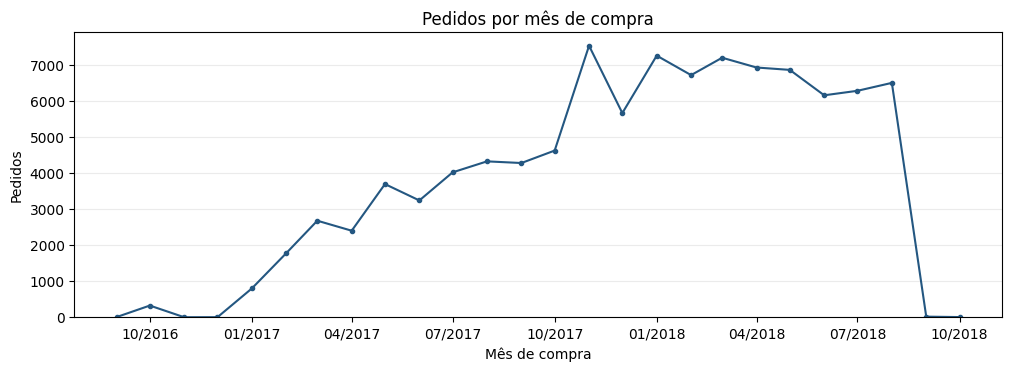

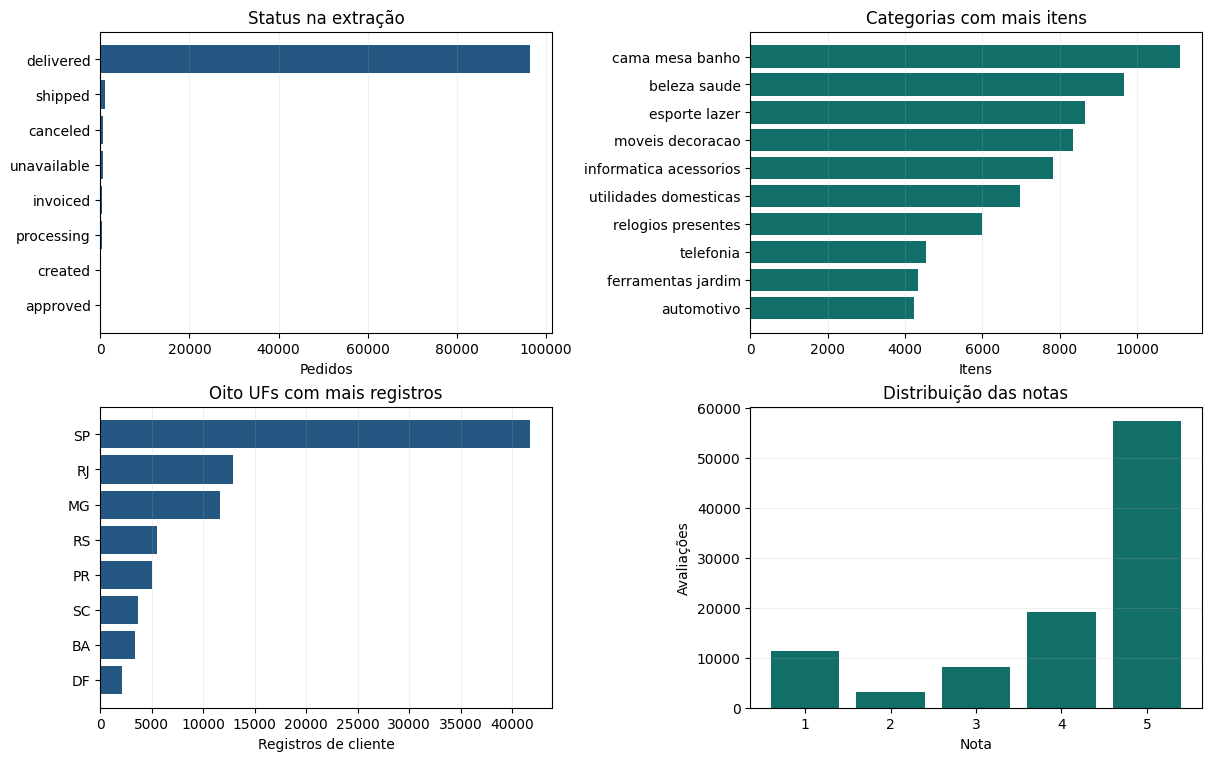

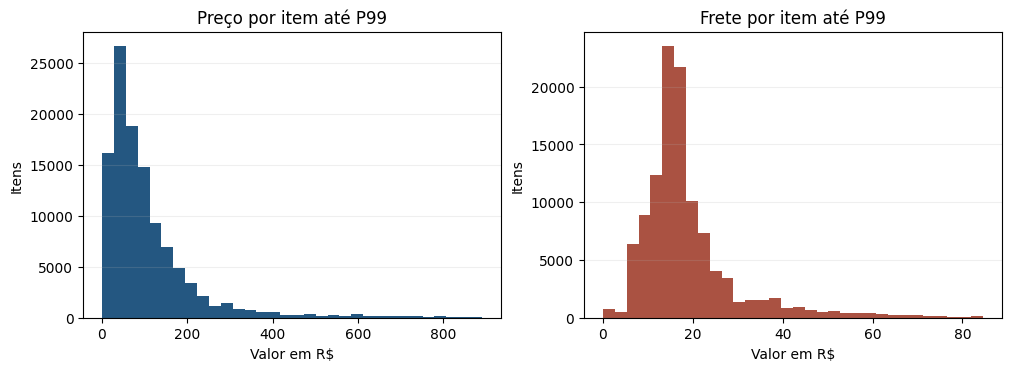

In [10]:
azul = "#245781"
verde = "#126e68"
terracota = "#aa5242"


def barras_horizontais(eixo, serie, titulo, unidade, cor):
    """Desenha um ranking horizontal, com o maior volume no topo."""
    ordenada = serie.iloc[::-1]
    rotulos = [str(rotulo).replace("_", " ") for rotulo in ordenada.index]
    eixo.barh(rotulos, ordenada.to_numpy(), color=cor)
    eixo.set(title=titulo, xlabel=unidade)
    eixo.grid(axis="x", alpha=.20)


fig, eixo = plt.subplots(figsize=(10, 3.6), layout="constrained")
eixo.plot(mensal.index.to_timestamp(), mensal["pedidos"], marker="o", ms=3, color=azul)
eixo.set(title="Pedidos por mês de compra", xlabel="Mês de compra", ylabel="Pedidos", ylim=(0, None))
eixo.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
eixo.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
eixo.grid(axis="y", alpha=.25)
plt.show()

fig, eixos = plt.subplots(2, 2, figsize=(12, 7.5), layout="constrained")
barras_horizontais(eixos[0, 0], status_contagem["pedidos"], "Status na extração", "Pedidos", azul)
barras_horizontais(eixos[0, 1], rank_categorias["itens"], "Categorias com mais itens", "Itens", verde)
barras_horizontais(eixos[1, 0], ufs_clientes["registros de cliente"].head(8), "Oito UFs com mais registros",
                   "Registros de cliente", azul)
eixos[1, 1].bar(notas_contagem.index.astype(str), notas_contagem["avaliações"], color=verde)
eixos[1, 1].set(title="Distribuição das notas", xlabel="Nota", ylabel="Avaliações")
eixos[1, 1].grid(axis="y", alpha=.20)
plt.show()

fig, eixos = plt.subplots(1, 2, figsize=(10, 3.6), layout="constrained")
for eixo, coluna, titulo, cor in zip(
    eixos, ["price", "freight_value"], ["Preço por item", "Frete por item"], [azul, terracota], strict=True
):
    valores = itens[coluna].dropna()
    limite = valores.quantile(.99)
    eixo.hist(valores[valores.le(limite)], bins=32, color=cor)
    eixo.set(title=f"{titulo} até P99", xlabel="Valor em R$", ylabel="Itens")
    eixo.grid(axis="y", alpha=.20)
plt.show()

Os histogramas mostram até o percentil 99 para dar visibilidade à região de maior concentração. Os máximos e todos os registros continuam representados nas estatísticas da seção 1.

### Atraso e avaliações

A taxa principal usa pedidos com status `delivered` e datas real e prevista legíveis. Há atraso quando o **dia de calendário** da entrega é posterior ao dia previsto. A previsão costuma estar gravada à meia-noite, por isso a comparação por horário é mostrada como cenário alternativo. Cada resultado conserva o denominador explícito.

A leitura por nota usa linhas de avaliações vinculadas aos pedidos elegíveis. A cobertura de avaliação é apresentada por pedido para evidenciar que as duas unidades de contagem são diferentes.

In [11]:
elegiveis = entregue & entrega.notna() & previsao.notna()
dias_vs_previsao = (entrega.dt.normalize() - previsao.dt.normalize()).dt.days
atraso_calendario = dias_vs_previsao.gt(0)
sequencia_valida = ~(entrega.lt(compra) | entrega.lt(postagem) | previsao.dt.normalize().lt(compra.dt.normalize()))
opcoes_atraso = [
    ("dia de calendário", elegiveis, atraso_calendario),
    ("horário gravado", elegiveis, entrega.gt(previsao)),
    ("dia de calendário, sem sequências sinalizadas", elegiveis & sequencia_valida, atraso_calendario),
]
resumo_atraso = pd.DataFrame([
    {"critério": nome, "pedidos elegíveis": mascara.sum(), "atrasados": (mascara & atrasos).sum()}
    for nome, mascara, atrasos in opcoes_atraso
]).set_index("critério")
resumo_atraso["% atrasados"] = resumo_atraso["atrasados"] * 100 / resumo_atraso["pedidos elegíveis"]
mostrar("Frequência de atraso e sensibilidade ao critério", resumo_atraso)

prazos = dias_vs_previsao[elegiveis]
resumo_prazo = pd.Series({
    "status delivered": entregue.sum(),
    "delivered fora do denominador por falta de data": (entregue & ~elegiveis).sum(),
    "entregues antes do dia previsto": prazos.lt(0).sum(),
    "entregues no dia previsto": prazos.eq(0).sum(),
    "entregues depois do dia previsto": prazos.gt(0).sum(),
    "mediana de dias de atraso, entre atrasados": prazos[prazos.gt(0)].median(),
    "P95 de dias de atraso, entre atrasados": prazos[prazos.gt(0)].quantile(.95),
}, name="valor").to_frame()
assert prazos.lt(0).sum() + prazos.eq(0).sum() + prazos.gt(0).sum() == elegiveis.sum()
mostrar("Composição do prazo na comparação por dia de calendário", resumo_prazo)

atraso_por_pedido = pd.Series(
    atraso_calendario.loc[elegiveis].to_numpy(),
    index=pedidos.loc[elegiveis, "order_id"],
    name="atraso",
)
notas_elegiveis = pd.DataFrame({
    "atraso": avaliacoes["order_id"].map(atraso_por_pedido),
    "nota": notas,
    "nota 1 ou 2": notas.isin([1, 2]),
    "pedido": avaliacoes["order_id"],
}).dropna(subset=["atraso", "nota"])
notas_por_prazo = notas_elegiveis.groupby("atraso").agg(
    **{"linhas com nota": ("nota", "size"), "pedidos com nota": ("pedido", "nunique"),
       "nota média": ("nota", "mean"), "% de notas 1 ou 2": ("nota 1 ou 2", "mean")}
)
notas_por_prazo["% de notas 1 ou 2"] *= 100
notas_por_prazo["pedidos elegíveis"] = atraso_por_pedido.value_counts()
notas_por_prazo["% de pedidos com nota"] = (
    notas_por_prazo["pedidos com nota"] * 100 / notas_por_prazo["pedidos elegíveis"]
)
notas_por_prazo = notas_por_prazo.rename(index={False: "No prazo ou antes", True: "Após o prazo"})
mostrar("Notas associadas a pedidos elegíveis, por prazo por dia de calendário", notas_por_prazo)

**Frequência de atraso e sensibilidade ao critério**

,pedidos elegíveis,atrasados,% atrasados
critério,,,
dia de calendário,96470,6534,6.7731
horário gravado,96470,7826,8.1124
"dia de calendário, sem sequências sinalizadas",96447,6534,6.7747


**Composição do prazo na comparação por dia de calendário**

,valor
status delivered,96478.0
delivered fora do denominador por falta de data,8.0
entregues antes do dia previsto,88644.0
entregues no dia previsto,1292.0
entregues depois do dia previsto,6534.0
"mediana de dias de atraso, entre atrasados",7.0
"P95 de dias de atraso, entre atrasados",31.0


**Notas associadas a pedidos elegíveis, por prazo por dia de calendário**

,linhas com nota,pedidos com nota,nota média,% de notas 1 ou 2,pedidos elegíveis,% de pedidos com nota
atraso,,,,,,
No prazo ou antes,89944,89443,4.290,9.2791,89936,99.4518
Após o prazo,6409,6381,2.271,62.4122,6534,97.6584


Diferenças nas notas descrevem uma associação nesta amostra. Categoria, região, época, cobertura das avaliações ou outros fatores podem influenciar a comparação. Uma regra futura de uma nota por pedido pode alterar o resultado.

## 5. Continuidade

- [Dicionário de dados](../docs/data_dictionary.md)
- [Relacionamentos e granularidade](../docs/source_relationships.md)
- [Relatório de qualidade](../reports/data_quality_report.md)
- [Descobertas e perguntas de negócio](../reports/eda_findings.md)